# 05 Občan zdaj in naslednjih 12 ur

**Namen:** informirati in spodbuditi ravnanje (kdaj prezračiti, kdaj na sprehod, kdaj naj ranljivi ostanejo notri). **Ciljna skupina:** občani.

Za poljubno točko v Ljubljani sestavimo kratko, prijazno sporočilo iz tega, kar imamo:

| Vhod | Vrsta | Datoteka |
|---|---|---|
| zadnja urna vrednost najbližje postaje ARSO | **meritev** | `01_meritve/arso_lj_pm_urno_*.csv` |
| zadnja vrednost najbližjega občanskega senzorja po umerjanju | **ocena** | `01_meritve/senzorji_umerjeno_urno.csv.gz` |
| ali je trenutno inverzija (Pasja ravan toplejša od Bežigrada) | **meritev** | `03_vreme_inverzija/inverzija_urno_*.csv` |
| tipičen potek po urah dneva iz zadnjih treh zim v podobnih razmerah | **statistika meritev** | izpeljano tu |
| smer naslednjih ur po CAMS | **model** | `02_modeli/cams_openmeteo_*.csv` |
| smer naslednjih ur po CAMx ARSO (4,4 km), za pretekle dni | **model** | `02_modeli/camx/camx_tocke_urno_*.csv` |

Vsako sporočilo nosi vir in čas. Ne obljubljamo natančnosti, ki je nimamo: vrednost na točki med postajami je ocena.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.insert(0, ".")
from paket import *
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)

arso = nalozi_arso()                                  # meritev, vse tri postaje, do 17. 11. 2026
senz = nalozi_senzorje_umerjene()                     # ocena (samo zanesljive naprave)
inv = nalozi_inverzijo()[["time_utc", "inv_pasja_ravan", "temp_lj_bezigrad", "wind_speed_lj_bezigrad"]]
cams = nalozi_cams("E403")                            # model
camx = nalozi_camx("E403")                            # model ARSO, 4,4 km; vse tri postaje so v isti celici
print(f"ARSO do {arso.time_utc.max():%d. %m. %Y %H:%M} UTC; senzorjev z umerjanjem: {senz.sensor_id.nunique()}; CAMS do {cams.time_utc.max():%d. %m. %Y}; CAMx do {camx.time_utc.max():%d. %m. %Y}")

ARSO do 17. 11. 2026 10:00 UTC; senzorjev z umerjanjem: 10; CAMS do 12. 11. 2026; CAMx do 18. 11. 2026


## 1. Razredi kakovosti zraka

Uporabimo pet razredov po urnih vrednostih (približek lestvice, ki jo za indeks kakovosti zraka uporablja ARSO; meje v µg/m³):

| razred | PM2.5 | PM10 | pomen |
|---|---|---|---|
| 1 dobro | ≤ 10 | ≤ 20 | brez omejitev |
| 2 zadovoljivo | ≤ 20 | ≤ 40 | brez omejitev |
| 3 zmerno | ≤ 25 | ≤ 50 | občutljivi naj skrajšajo napor zunaj |
| 4 slabo | ≤ 50 | ≤ 100 | občutljivi ostanejo notri, ostali manj napora |
| 5 zelo slabo | > 50 | > 100 | vsi omejijo čas zunaj |

Razred točke je slabši od obeh (PM2.5, PM10). Funkcija `razred_iqz` je v `paket.py`.

In [2]:
def stanje_na_tocki(lat, lon, t, max_zamik_h=3, max_senzor_km=2.5):
    """Zadnje znano stanje na točki ob času t (UTC): najbližja postaja ARSO (meritev) in najbližji zanesljiv senzor (ocena)."""
    t = pd.Timestamp(t).tz_localize("UTC") if pd.Timestamp(t).tzinfo is None else pd.Timestamp(t)
    kod, d_post = najblizja_postaja(lat, lon)
    a = arso[(arso.station_code == kod) & (arso.time_utc <= t) & (arso.time_utc > t - pd.Timedelta(hours=max_zamik_h))].dropna(subset=["pm25"]).tail(1)
    out = dict(lat=lat, lon=lon, cas=t, postaja=POSTAJE[kod]["ime"], postaja_km=round(d_post, 1),
               postaja_pm25=float(a.pm25.iloc[0]) if len(a) else np.nan, postaja_pm10=float(a.pm10.iloc[0]) if len(a) else np.nan,
               postaja_cas=a.time_utc.iloc[0] if len(a) else pd.NaT)
    s = senz[(senz.time_utc <= t) & (senz.time_utc > t - pd.Timedelta(hours=max_zamik_h))].dropna(subset=["pm25_cal"]).copy()
    if len(s):
        s["km"] = [haversine_km(lat, lon, la, lo) for la, lo in zip(s.lat, s.lon)]
        s = s[s.km <= max_senzor_km].sort_values(["km", "time_utc"], ascending=[True, False])
    if len(s):
        r = s.iloc[0]
        out.update(senzor_id=int(r.sensor_id), senzor_km=round(r.km, 1), senzor_pm25_cal=float(r.pm25_cal), senzor_pm25_surovo=float(r.pm25), senzor_cas=r.time_utc)
    else:
        out.update(senzor_id=None, senzor_km=np.nan, senzor_pm25_cal=np.nan, senzor_pm25_surovo=np.nan, senzor_cas=pd.NaT)
    i = inv[(inv.time_utc <= t) & (inv.time_utc > t - pd.Timedelta(hours=max_zamik_h))].dropna(subset=["inv_pasja_ravan"]).tail(1)
    out["inverzija"] = bool(i.inv_pasja_ravan.iloc[0]) if len(i) else None
    # ocena na točki: senzor, če je blizu in zanesljiv, sicer postaja
    out["pm25_tocka"] = out["senzor_pm25_cal"] if not np.isnan(out["senzor_pm25_cal"]) else out["postaja_pm25"]
    out["vir_tocke"] = "ocena iz umerjenega občanskega senzorja" if not np.isnan(out["senzor_pm25_cal"]) else "meritev najbližje postaje ARSO"
    out["razred"] = razred_iqz(pm25=out["pm25_tocka"], pm10=out["postaja_pm10"])
    return out

TOCKE = {"Vič (Rožna dolina)": (46.045, 14.480), "Center (Prešernov trg)": (46.051, 14.506), "Fužine": (46.052, 14.575)}
T0 = pd.Timestamp("2026-01-20 18:00", tz="UTC")   # večer v najbolj onesnaženem tednu zime 2025/26
pd.DataFrame([stanje_na_tocki(la, lo, T0) for la, lo in TOCKE.values()], index=TOCKE.keys()).T

,Vič (Rožna dolina),Center (Prešernov trg),Fužine
lat,46.045,46.051,46.052
lon,14.48,14.506,14.575
cas,2026-01-20 18:00:00+00:00,2026-01-20 18:00:00+00:00,2026-01-20 18:00:00+00:00
postaja,LJ Vič,LJ Bežigrad,LJ Bežigrad
postaja_km,1.1,1.7,5.0
postaja_pm25,42.29,36.855,36.855
postaja_pm10,54.145,44.377,44.377
postaja_cas,2026-01-20 18:00:00+00:00,2026-01-20 18:00:00+00:00,2026-01-20 18:00:00+00:00
senzor_id,9821,64688,96479
senzor_km,0.7,2.4,1.0


## 2. Naslednjih 12 ur: tipičen potek v podobnih razmerah

Napovedi na točki nimamo. Imamo pa tri zime meritev, iz katerih izračunamo, kako se PM2.5 na najbližji postaji **tipično** spreminja po urah dneva v podobnih razmerah (inverzija da/ne, delovnik/vikend). Tipičen potek sidramo na trenutno vrednost in dodamo smer, ki jo kaže CAMS (model) za naslednje ure. Rezultat je **ocena**, ki pove predvsem *kdaj* bo bolje in kdaj slabše, ne natančno koliko.

In [3]:
zime = zima(arso[arso.time_utc >= "2023-11-01"]).merge(inv[["time_utc", "inv_pasja_ravan"]], on="time_utc", how="left").dropna(subset=["pm25", "inv_pasja_ravan"])
zime["ura"] = zime.time_utc.dt.hour
zime["vikend"] = zime.time_utc.dt.dayofweek >= 5
TIPICNI = zime.groupby(["station_code", "inv_pasja_ravan", "vikend", "ura"]).pm25.mean()

def naslednjih_12h(st, cams_df=cams, ure=12):
    """Vrne DataFrame z urami t+1..t+ure: tipična vrednost (sidrana na trenutno) in smer CAMS. Ocena."""
    t = st["cas"]; kod = [k for k, v in POSTAJE.items() if v["ime"] == st["postaja"]][0]
    inv_flag = 1.0 if st["inverzija"] else 0.0
    vikend = t.dayofweek >= 5
    prof = TIPICNI.loc[(kod, inv_flag, vikend)]
    zdaj = st["pm25_tocka"]
    faktor = zdaj / prof.loc[t.hour] if prof.loc[t.hour] > 0 else 1.0
    faktor = float(np.clip(faktor, 0.3, 3.0))          # sidranje, a ne pretirano
    rows = []
    c0 = cams_df[cams_df.time_utc == t].cams_pm25
    for h in range(1, ure + 1):
        th = t + pd.Timedelta(hours=h)
        c = cams_df[cams_df.time_utc == th].cams_pm25
        smer = float(c.iloc[0] / c0.iloc[0]) if len(c) and len(c0) and c0.iloc[0] > 0 else np.nan
        rows.append(dict(time_utc=th, ura_lokalno=(th.hour + 1) % 24, tipicno=prof.loc[th.hour] * faktor, cams_smer=smer))
    df = pd.DataFrame(rows)
    df["ocena_pm25"] = df.tipicno * np.where(df.cams_smer.notna(), (1 + df.cams_smer) / 2, 1)   # polovica teže smeri CAMS
    return df

st_vic = stanje_na_tocki(*TOCKE["Vič (Rožna dolina)"], T0)
n12 = naslednjih_12h(st_vic)
n12.round(1)

,time_utc,ura_lokalno,tipicno,cams_smer,ocena_pm25
0,2026-01-20 19:00:00+00:00,20,46.6,1.2,50.6
1,2026-01-20 20:00:00+00:00,21,49.2,1.3,56.7
2,2026-01-20 21:00:00+00:00,22,50.3,1.3,59.0
3,2026-01-20 22:00:00+00:00,23,50.6,1.4,61.3
4,2026-01-20 23:00:00+00:00,0,46.1,1.4,56.0
5,2026-01-21 00:00:00+00:00,1,41.1,1.1,43.3
6,2026-01-21 01:00:00+00:00,2,38.5,0.8,34.3
7,2026-01-21 02:00:00+00:00,3,35.1,0.7,29.4
8,2026-01-21 03:00:00+00:00,4,32.6,0.7,27.6
9,2026-01-21 04:00:00+00:00,5,30.7,0.7,25.5


### Smer iz modela CAMx (ARSO, 4,4 km) s popravkom pristranskosti

CAMS ima celico 10 km, CAMx ARSO 4,4 km in napoved za isti dan (ure +1 … +24, zagon ob 00 UTC). Model za Ljubljano **precenjuje** (v zimah 2023/24–2025/26 za okoli 8 µg/m³ dnevno) in ima jutranji vrh, ki ga meritve nimajo, zato ga pred uporabo popravimo: od vrednosti odštejemo povprečno razliko model − meritev zadnjih 30 dni na najbližji postaji. Popravljen model je **ocena**. Isto funkcijo `naslednjih_12h` pokličemo z CAMx namesto CAMS. Ker izvoz vsebuje samo ure istega dne (do 24 UTC), smer po polnoči odpade in ostane tipičen potek; to se popravi, ko ARSO doda ure +25 … +48. Decembra 2025 CAMx nima PM2.5 (luknja v izvozu).

In [4]:
_cm = camx[["time_utc", "camx_pm25"]].merge(arso[["time_utc", "station_code", "pm25"]], on="time_utc")
_cm["dan"] = _cm.time_utc.dt.floor("D")
_d = _cm.groupby(["station_code", "dan"])[["camx_pm25", "pm25"]].mean()
BIAS_CAMX = {k: (g.droplevel(0).camx_pm25 - g.droplevel(0).pm25).rolling("30D", min_periods=10).mean().shift(1) for k, g in _d.groupby(level=0)}

def camx_kot_smer(kod, t, dni=30):
    """CAMx v celici postaje za dan t (ure +1 … +24), minus pristranskost zadnjih `dni` dni; vrne stolpca kot CAMS (time_utc, cams_pm25). Ocena."""
    dan = t.floor("D")
    b = BIAS_CAMX[kod].get(dan, np.nan)
    c = camx[camx.run_utc == dan][["time_utc", "camx_pm25"]].copy()
    c["cams_pm25"] = (c.camx_pm25 - (0 if np.isnan(b) else b)).clip(lower=1)
    return c, b

kod_vic = [k for k, v in POSTAJE.items() if v["ime"] == st_vic["postaja"]][0]
cx_vic, b_vic = camx_kot_smer(kod_vic, T0)
n12c = naslednjih_12h(st_vic, cams_df=cx_vic)
print(f"pristranskost CAMx proti {st_vic['postaja']} zadnjih 30 dni: {b_vic:+.1f} µg/m³ (odšteta)")
pd.DataFrame({"ura (lokalno)": n12.ura_lokalno, "tipično": n12.tipicno, "s smerjo CAMS": n12.ocena_pm25, "s smerjo CAMx (popr.)": n12c.ocena_pm25}).round(1).set_index("ura (lokalno)").T

pristranskost CAMx proti LJ Vič zadnjih 30 dni: +8.3 µg/m³ (odšteta)


ura (lokalno),20,21,22,23,0,1,2,3,4,5,6,7
tipično,46.6,49.2,50.3,50.6,46.1,41.1,38.5,35.1,32.6,30.7,29.6,29.6
s smerjo CAMS,50.6,56.7,59.0,61.3,56.0,43.3,34.3,29.4,27.6,25.5,25.0,25.2
s smerjo CAMx (popr.),48.5,53.9,53.0,51.2,46.2,41.1,38.5,35.1,32.6,30.7,29.6,29.6


## 3. Sporočilo v naravnem jeziku

Tri ravni (dobro, zmerno, slabo), prijazen ton, brez moraliziranja, vedno vir in čas. Ure so lokalne (UTC + 1).

In [5]:
def sporocilo(st, n12):
    r = st["razred"]; ime_r = RAZRED_IME.get(r, "neznano")
    vir = st["vir_tocke"]; cas = st["cas"].tz_convert("Europe/Ljubljana").strftime("%d. %m. ob %H:%M")
    v = st["pm25_tocka"]
    if np.isnan(v):
        return f"Za to točko trenutno nimamo podatka ({cas}). Poglejte najbližjo postajo {st['postaja']} ({st['postaja_km']} km)."
    najn = n12.loc[n12.ocena_pm25.idxmin()]; najv = n12.loc[n12.ocena_pm25.idxmax()]
    trend = "se bo po oceni izboljšal" if n12.ocena_pm25.iloc[-1] < 0.8 * v else ("se bo po oceni poslabšal" if n12.ocena_pm25.iloc[-1] > 1.25 * v else "bo po oceni ostal podoben")
    glava = {1: "Zrak je dober", 2: "Zrak je zadovoljiv", 3: "Zrak je zmerno onesnažen", 4: "Zrak je slab", 5: "Zrak je zelo slab"}.get(r, "Stanje zraka")
    nasvet = {1: "Uživajte zunaj.", 2: "Brez omejitev; občutljivi naj spremljajo stanje.",
              3: "Če imate astmo, srčno bolezen ali ste starejši, naj bo napor zunaj krajši.",
              4: "Občutljivi raje ostanite notri, ostali si privoščite lažje aktivnosti zunaj.",
              5: "Danes zvečer raje ostanite notri; okna odprite le na kratko."}.get(r, "")
    prezraci = f"Najbolje prezračite okoli {int(najn.ura_lokalno):02d}:00 (pričakovano najnižje vrednosti), izogibajte se prezračevanju okoli {int(najv.ura_lokalno):02d}:00."
    inv_txt = " Nad mestom je temperaturna inverzija, zato se onesnaženje zadržuje pri tleh." if st["inverzija"] else ""
    return (f"{glava} ({ime_r}): PM2.5 okoli {v:.0f} µg/m³.{inv_txt} V naslednjih 12 urah {trend}. {nasvet} {prezraci}\n"
            f"  Vir: {vir} ({st['postaja']} {st['postaja_km']} km" + (f", senzor {st['senzor_id']} {st['senzor_km']} km" if st['senzor_id'] else "") + f"), stanje {cas}. Potek naslednjih ur je ocena iz preteklih zim in modela CAMS.")

for ime, (la, lo) in TOCKE.items():
    st = stanje_na_tocki(la, lo, T0)
    print(f"[{ime}]"); print(sporocilo(st, naslednjih_12h(st))); print()

[Vič (Rožna dolina)]
Zrak je slab (slabo): PM2.5 okoli 41 µg/m³. V naslednjih 12 urah se bo po oceni izboljšal. Občutljivi raje ostanite notri, ostali si privoščite lažje aktivnosti zunaj. Najbolje prezračite okoli 06:00 (pričakovano najnižje vrednosti), izogibajte se prezračevanju okoli 23:00.
  Vir: ocena iz umerjenega občanskega senzorja (LJ Vič 1.1 km, senzor 9821 0.7 km), stanje 20. 01. ob 19:00. Potek naslednjih ur je ocena iz preteklih zim in modela CAMS.



[Center (Prešernov trg)]
Zrak je slab (slabo): PM2.5 okoli 30 µg/m³. V naslednjih 12 urah se bo po oceni izboljšal. Občutljivi raje ostanite notri, ostali si privoščite lažje aktivnosti zunaj. Najbolje prezračite okoli 07:00 (pričakovano najnižje vrednosti), izogibajte se prezračevanju okoli 23:00.
  Vir: ocena iz umerjenega občanskega senzorja (LJ Bežigrad 1.7 km, senzor 64688 2.4 km), stanje 20. 01. ob 19:00. Potek naslednjih ur je ocena iz preteklih zim in modela CAMS.



[Fužine]
Zrak je slab (slabo): PM2.5 okoli 34 µg/m³. V naslednjih 12 urah se bo po oceni izboljšal. Občutljivi raje ostanite notri, ostali si privoščite lažje aktivnosti zunaj. Najbolje prezračite okoli 07:00 (pričakovano najnižje vrednosti), izogibajte se prezračevanju okoli 23:00.
  Vir: ocena iz umerjenega občanskega senzorja (LJ Bežigrad 5.0 km, senzor 96479 1.0 km), stanje 20. 01. ob 19:00. Potek naslednjih ur je ocena iz preteklih zim in modela CAMS.



## 4. Graf: zadnjih 24 ur in ocena naslednjih 12

Polna črta so meritve postaje (in umerjeni senzor, če obstaja), črtkana je ocena naslednjih ur, barvni pasovi so razredi.

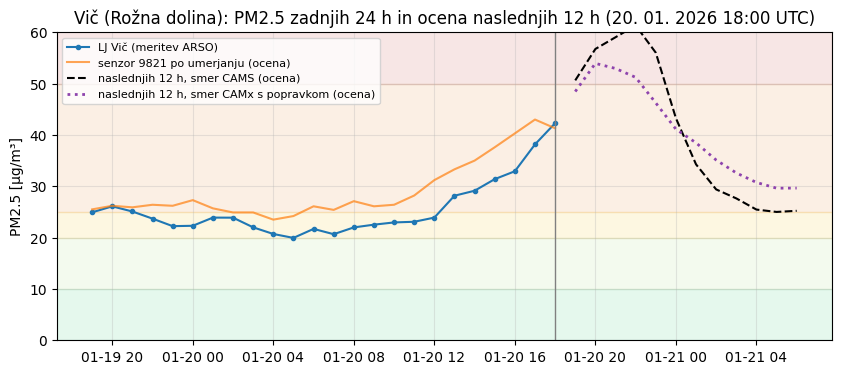

In [6]:
def graf(ime, st, n12, n12c=None):
    kod = [k for k, v in POSTAJE.items() if v["ime"] == st["postaja"]][0]
    t = st["cas"]
    a = arso[(arso.station_code == kod) & (arso.time_utc > t - pd.Timedelta(hours=24)) & (arso.time_utc <= t)]
    fig, ax = plt.subplots(figsize=(10, 4))
    for y0, y1, c in [(0, 10, "#2ecc71"), (10, 20, "#a3d977"), (20, 25, "#f1c40f"), (25, 50, "#e67e22"), (50, 120, "#c0392b")]:
        ax.axhspan(y0, y1, color=c, alpha=.12)
    ax.plot(a.time_utc, a.pm25, "-o", ms=3, label=f"{st['postaja']} (meritev ARSO)")
    if st["senzor_id"]:
        s = senz[(senz.sensor_id == st["senzor_id"]) & (senz.time_utc > t - pd.Timedelta(hours=24)) & (senz.time_utc <= t)]
        ax.plot(s.time_utc, s.pm25_cal, "-", alpha=.7, label=f"senzor {st['senzor_id']} po umerjanju (ocena)")
    ax.plot(n12.time_utc, n12.ocena_pm25, "--", color="k", label="naslednjih 12 h, smer CAMS (ocena)")
    if n12c is not None:
        ax.plot(n12c.time_utc, n12c.ocena_pm25, ":", color="#8e44ad", lw=2, label="naslednjih 12 h, smer CAMx s popravkom (ocena)")
    ax.axvline(t, color="gray", lw=1); ax.set_ylim(0, max(60, float(np.nanmax(a.pm25)) * 1.1))
    ax.set(title=f"{ime}: PM2.5 zadnjih 24 h in ocena naslednjih 12 h ({t:%d. %m. %Y %H:%M} UTC)", ylabel="PM2.5 [µg/m³]")
    ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=.3); plt.show()

graf("Vič (Rožna dolina)", st_vic, n12, n12c)

## 5. Kako dobro tipičen potek sploh napove naslednjih 12 ur?

Pošten test na zimi 2025/26: za vsako uro vzamemo stanje na Viču, ocenimo naslednjih 12 ur in primerjamo z meritvijo. Zanima nas predvsem, ali pravilno povemo, **katera ura bo najboljša** za prezračevanje (ali je ocenjena najnižja ura med tremi dejansko najnižjimi). Isto naredimo s smerjo iz CAMx s popravkom; test teče na izhodiščih, kjer CAMx PM2.5 obstaja (januar in februar 2026). Rezultat je poučen: finejša mreža sama po sebi ne pomaga. CAMx s preprostim popravkom je **slabši** od CAMS (večja napaka, podoben zadetek najboljše ure), ker ima lažni jutranji vrh in ker za izhodišča popoldne in zvečer do polnoči zmanjka ur (napoved sega le do 24 UTC). Z urami +25 … +48 in s popravkom po urah dneva bi bil rezultat drugačen; to je naloga za ekipe.

In [7]:
test = arso[(arso.station_code == "E404") & (arso.time_utc >= "2025-12-01") & (arso.time_utc < "2026-03-01")].dropna(subset=["pm25"]).set_index("time_utc").pm25
rez = {"smer CAMS": dict(ok=0, mae=[], n=0), "smer CAMx s popravkom": dict(ok=0, mae=[], n=0)}
for t in test.index[::6]:                               # vsaka šesta ura, da je hitro
    st = stanje_na_tocki(*TOCKE["Vič (Rožna dolina)"], t)
    if np.isnan(st["pm25_tocka"]) or st["inverzija"] is None:
        continue
    cx_t, _ = camx_kot_smer("E404", t)
    if len(cx_t) == 0 or cx_t.cams_pm25.isna().all():
        continue                                        # brez CAMx PM2.5 (december 2025) primerjava ni poštena
    for ime, cdf in [("smer CAMS", cams), ("smer CAMx s popravkom", cx_t)]:
        n12t = naslednjih_12h(st, cams_df=cdf)
        dej = test.reindex(n12t.time_utc)
        if dej.isna().sum() > 2:
            continue
        r = rez[ime]; r["n"] += 1
        r["mae"].append(float(np.nanmean(np.abs(n12t.ocena_pm25.values - dej.values))))
        najn = int(n12t.ocena_pm25.idxmin()); top3 = set(np.argsort(dej.values)[:3])
        r["ok"] += najn in top3
for ime, r in rez.items():
    print(f"{ime:22s}: {r['n']} izhodišč; MAE naslednjih 12 h {np.mean(r['mae']):.1f} µg/m³; "
          f"najboljša ura za prezračevanje med 3 dejansko najboljšimi v {r['ok']/r['n']:.0%} primerov (naključje: 25 %)")

smer CAMS             : 235 izhodišč; MAE naslednjih 12 h 11.6 µg/m³; najboljša ura za prezračevanje med 3 dejansko najboljšimi v 46% primerov (naključje: 25 %)
smer CAMx s popravkom : 235 izhodišč; MAE naslednjih 12 h 14.6 µg/m³; najboljša ura za prezračevanje med 3 dejansko najboljšimi v 43% primerov (naključje: 25 %)


## 6. V živo (potrebuje internet)

Ista logika z zadnjo uro ARSO in napovedjo Open-Meteo prek `v_zivo/zrak_v_zivo.py`. V živo ostane smer iz CAMS: ARSO polj CAMx ne objavlja v živo (na spletu so le slike), zato je CAMx v tem zvezku uporaben za pretekle dni in za učenje popravka. Če interneta ni, celica to pove in nadaljuje.

In [8]:
try:
    sys.path.insert(0, "../v_zivo"); import zrak_v_zivo as zv
    zadnja = zv.arso_zadnja_ura()
    lj = zadnja[zadnja.station_code.isin(POSTAJE)].set_index("station_code")
    nap = zv.napoved(*TOCKE["Vič (Rožna dolina)"], ure=12)
    v = float(lj.loc["E404", "pm25"]); r = razred_iqz(pm25=v, pm10=float(lj.loc["E404", "pm10"]))
    print(f"ZDAJ ({lj.loc['E404','time_local']:%d. %m. %H:%M} lokalno): Vič PM2.5 {v:.0f} µg/m³, razred {r} ({RAZRED_IME[r]}); vir: meritev ARSO.")
    print("CAMS napoved naslednjih 12 h (model), µg/m³:", nap.pm2_5.round(0).astype(int).tolist())
    print("višina mejne plasti (model, m):", nap.boundary_layer_height.round(0).astype(int).tolist())
except Exception as e:
    print("Podatkov v živo ni (ni interneta ali vir ne odgovarja):", type(e).__name__)

ZDAJ (18. 11. 14:00 lokalno): Vič PM2.5 4 µg/m³, razred 1 (dobro); vir: meritev ARSO.
CAMS napoved naslednjih 12 h (model), µg/m³: [10, 13, 18, 21, 25, 29, 31, 31, 26, 25, 25, 25]
višina mejne plasti (model, m): [110, 60, 95, 100, 55, 40, 30, 25, 15, 15, 15, 15]


## Kaj lahko ekipa iz tega naredi

1. **Aplikacija ali kartica "Zrak pri meni"**: lokacija uporabnika, sporočilo iz točke 3, graf iz točke 4; podatki v živo iz `v_zivo/`.
2. **Obvestila ob pravem času**: push ali Telegram ob prehodu v razred 4, in zvečer "jutri zjutraj prezračite ob 7h" iz tipičnega poteka.
3. **Boljša ocena naslednjih ur**: zamenjajte tipičen potek z modelom iz zvezka 03 (napoved); preverite na zimi 2025/26 kot v točki 5.
4. **Umerjanje CAMx**: popravek pristranskosti tu je najpreprostejši možen (ena številka). Naučite popravek po urah dneva in po razmerah (inverzija, veter) iz `02_modeli/camx/camx_tocke_urno_*.csv` proti meritvam; ko ARSO doda ure +25 … +48, isto za napoved za jutri.
5. **Prostorska ocena med postajami**: več kot tri točke; uporabite umerjene senzorje in relief (zvezek 04), a vedno z oznako "ocena".
6. **Jezik in ranljive skupine**: ločena sporočila za starše, starejše, športnike; preverite razumljivost z resničnimi uporabniki.